In [2]:
# ==========================================================
# CELL 1: IMPORTING REQUIRED LIBRARIES
# ==========================================================

import os
import warnings
import joblib
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [4]:
# ==========================================================
# CELL 2: PROJECT DIRECTORY
# ==========================================================

PROJECT_DIR = Path.home() / "workspace" / "DryBeanProject"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = PROJECT_DIR / "Dry_Bean_Dataset.csv"

MODEL_DIR = PROJECT_DIR / "model"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset location:", DATA_FILE)
print("Model directory:", MODEL_DIR)

Project directory: /home/s2026aj05188/workspace/DryBeanProject
Dataset location: /home/s2026aj05188/workspace/DryBeanProject/Dry_Bean_Dataset.csv
Model directory: /home/s2026aj05188/workspace/DryBeanProject/model


In [6]:
# ==========================================================
# CELL 3: LOADING DRY BEAN DATASET
# ==========================================================

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully!")

print("\nDataset dimensions:", df.shape)

print("\nFirst five observations:")

display(df.head())

Dataset loaded successfully!

Dataset dimensions: (13611, 17)

First five observations:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [8]:
## ==========================================================
# CELL 4: DATASET STRUCTURE
# ==========================================================

print("NUMBER OF ROWS:", df.shape[0])

print("NUMBER OF COLUMNS:", df.shape[1])

print("\nCOLUMN NAMES:")

print(df.columns.tolist())

print("\nDATA TYPES:")

print(df.dtypes)

print("\nDATASET INFORMATION:")

df.info()

NUMBER OF ROWS: 13611
NUMBER OF COLUMNS: 17

COLUMN NAMES:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

DATA TYPES:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  ----- 

## 5. Descriptive Statistical Analysis

Descriptive statistical analysis is performed to understand the
distribution and characteristics of the numerical variables.

Measures such as mean, median, standard deviation, minimum,
maximum and quartiles help identify the central tendency,
dispersion and spread of the observations.

This analysis provides an initial understanding of the
dataset before performing further exploratory analysis
and machine learning modelling.

In [11]:
# ==========================================================
# CELL 5: DESCRIPTIVE STATISTICAL ANALYSIS
# ==========================================================

# Generate descriptive statistics for numerical variables

descriptive_stats = df.describe().T

# Add median separately
descriptive_stats['Median'] = df.median(numeric_only=True)

# Display the results
print("DESCRIPTIVE STATISTICAL SUMMARY")

display(descriptive_stats.round(4))

DESCRIPTIVE STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max,Median
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000,44652.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700,794.9410
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602,296.8834
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985,192.4317
AspectRatio,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303,1.5511
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114,0.7644
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000,45178.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744,238.4380
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662,0.7599
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,0.9883


## 6. Missing Value Analysis

Missing value analysis is performed to identify whether any
observations contain incomplete information.

The presence of missing values can affect statistical
analysis and machine learning model performance.

The number and percentage of missing values are calculated
for each variable.

In [14]:
# ==========================================================
# CELL 6: MISSING VALUE ANALYSIS
# ==========================================================

missing_values = pd.DataFrame()

missing_values['Missing Count'] = df.isnull().sum()

missing_values['Missing Percentage'] = (
    df.isnull().sum() / len(df)
) * 100

print("MISSING VALUE ANALYSIS")

display(missing_values)

MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
Area,0,0.0
Perimeter,0,0.0
MajorAxisLength,0,0.0
MinorAxisLength,0,0.0
AspectRatio,0,0.0
Eccentricity,0,0.0
ConvexArea,0,0.0
EquivDiameter,0,0.0
Extent,0,0.0
Solidity,0,0.0


## 7. Duplicate Observation Analysis

Duplicate observations refer to records that appear more
than once in the dataset.

Identifying duplicate records is important because repeated
observations may introduce bias into the analysis and
affect the reliability of machine learning models.

The number of duplicate observations is calculated.

In [19]:
# ==========================================================
# CELL 7: DUPLICATE VALUE ANALYSIS
# ==========================================================

duplicate_count = df.duplicated().sum()

print("Total observations:", len(df))

print("Number of duplicate observations:", duplicate_count)

print(
    "Percentage of duplicate observations:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Total observations: 13611
Number of duplicate observations: 68
Percentage of duplicate observations: 0.4996 %


# ==========================================================
# CELL 7: DUPLICATE VALUE ANALYSIS
# ==========================================================

duplicate_count = df.duplicated().sum()

print("Total observations:", len(df))

print("Number of duplicate observations:", duplicate_count)

print(
    "Percentage of duplicate observations:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

In [22]:
# ==========================================================
# CELL 8: CLASS DISTRIBUTION
# ==========================================================

class_counts = df['Class'].value_counts()

class_percentage = (
    df['Class'].value_counts(normalize=True) * 100
)

class_distribution = pd.DataFrame({
    'Number of Observations': class_counts,
    'Percentage (%)': class_percentage
})

print("DISTRIBUTION OF DRY BEAN CLASSES")

display(class_distribution.round(2))

DISTRIBUTION OF DRY BEAN CLASSES


,Number of Observations,Percentage (%)
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


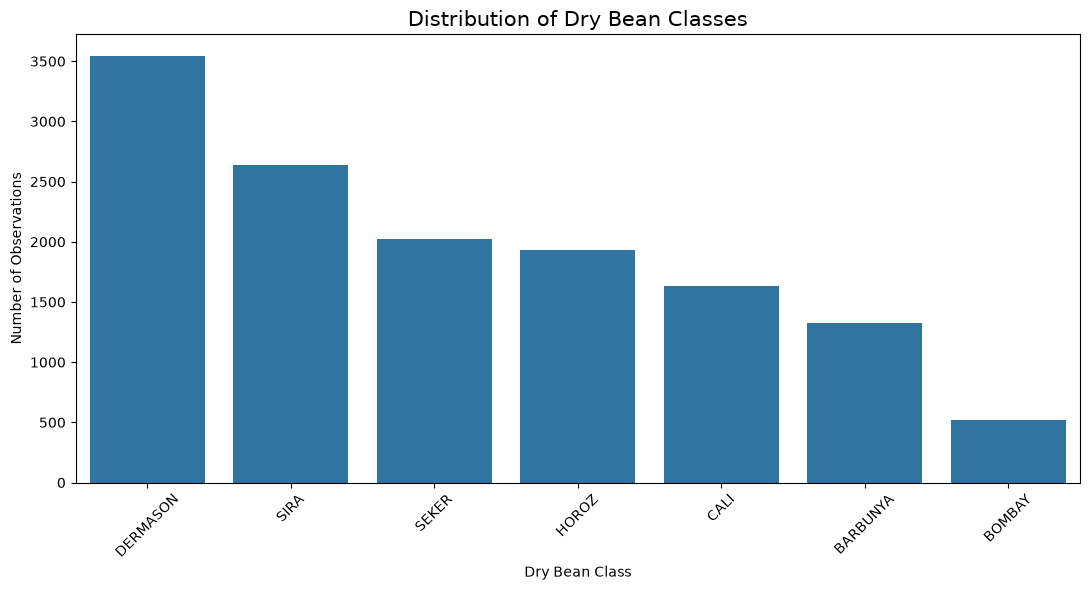

In [24]:
# ==========================================================
# CELL 9: CLASS DISTRIBUTION VISUALISATION
# ==========================================================

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='Class',
    order=df['Class'].value_counts().index
)

plt.title(
    'Distribution of Dry Bean Classes',
    fontsize=15
)

plt.xlabel('Dry Bean Class')

plt.ylabel('Number of Observations')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

## 10. Data Preprocessing

Data preprocessing involves preparing the dataset for machine
learning model development.

The dataset contains 16 numerical independent variables and
one categorical dependent variable (Class).

The independent variables will be used as predictors, while
the Class variable will serve as the target for classification.

The dataset will subsequently be divided into training and
testing subsets.

In [27]:
# ==========================================================
# CELL 10: SEPARATING FEATURES AND TARGET
# ==========================================================

# Independent variables
X = df.drop(columns=['Class'])

# Dependent variable
y = df['Class']

print("FEATURE MATRIX (X)")
print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nTARGET VARIABLE (y)")
print("Number of observations:", y.shape[0])
print("Number of unique classes:", y.nunique())

print("\nBean categories:")
print(y.unique())

FEATURE MATRIX (X)
Number of observations: 13611
Number of features: 16

TARGET VARIABLE (y)
Number of observations: 13611
Number of unique classes: 7

Bean categories:
<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [29]:
# ==========================================================
# CELL 11: DATA VALIDATION
# ==========================================================

print("Checking missing values in features:")

print(X.isnull().sum().sum())

print("\nChecking missing values in target:")

print(y.isnull().sum())

print("\nChecking infinite values:")

print(np.isinf(X.select_dtypes(include=np.number)).sum().sum())

print("\nChecking duplicate observations:")

print(df.duplicated().sum())

print("\nFeature data types:")

print(X.dtypes.value_counts())

Checking missing values in features:
0

Checking missing values in target:
0

Checking infinite values:
0

Checking duplicate observations:
68

Feature data types:
float64    14
int64       2
Name: count, dtype: int64


## 11. Train-Test Split

The dataset is divided into training and testing subsets
using an 80:20 ratio.

The training dataset is used for model development, while
the testing dataset is reserved for evaluating model
performance on unseen observations.

Stratified sampling is employed to maintain the proportion
of the seven bean categories in both subsets.

A random_state of 42 is used to ensure reproducibility.

In [32]:
# ==========================================================
# CELL 12: TRAIN-TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING AND TESTING DATASET DETAILS")

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining dataset percentage:",
      round(len(X_train)/len(df)*100, 2), "%")

print("Testing dataset percentage:",
      round(len(X_test)/len(df)*100, 2), "%")

TRAINING AND TESTING DATASET DETAILS

Training features: (10888, 16)
Testing features: (2723, 16)

Training target: (10888,)
Testing target: (2723,)

Training dataset percentage: 79.99 %
Testing dataset percentage: 20.01 %


In [34]:
# ==========================================================
# CELL 13: VERIFYING STRATIFIED SAMPLING
# ==========================================================

train_distribution = y_train.value_counts(normalize=True) * 100

test_distribution = y_test.value_counts(normalize=True) * 100

distribution_comparison = pd.DataFrame({
    'Original Dataset (%)': y.value_counts(normalize=True) * 100,
    'Training Dataset (%)': train_distribution,
    'Testing Dataset (%)': test_distribution
})

print("CLASS DISTRIBUTION COMPARISON")

display(distribution_comparison.round(2))

CLASS DISTRIBUTION COMPARISON


,Original Dataset (%),Training Dataset (%),Testing Dataset (%)
Class,,,
DERMASON,26.05,26.06,26.04
SIRA,19.37,19.37,19.35
SEKER,14.89,14.89,14.91
HOROZ,14.17,14.16,14.18
CALI,11.98,11.98,11.97
BARBUNYA,9.71,9.71,9.73
BOMBAY,3.84,3.84,3.82


## 12. Machine Learning Model Development

Five supervised machine learning classification algorithms
are implemented to classify dry beans into seven categories.

The algorithms selected are:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbours (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

Different preprocessing pipelines are employed depending
on the requirements of each algorithm.

Feature standardisation is applied to Logistic Regression,
KNN and SVM, while Decision Tree and Gaussian Naive Bayes
are implemented without feature scaling.

Median imputation is incorporated within the pipelines
to handle any missing numerical feature values.

In [37]:
# ==========================================================
# CELL 14: DEFINING FIVE MACHINE LEARNING MODELS
# ==========================================================

models = {

    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    'KNN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    'Naive Bayes': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', GaussianNB())
    ]),

    'Support Vector Machine': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='rbf',
            C=1.0,
            gamma='scale',
            probability=True,
            random_state=42
        ))
    ])

}

print("Five machine learning models defined successfully!")

for model_name in models:

    print(model_name)

Five machine learning models defined successfully!
Logistic Regression
Decision Tree
KNN
Naive Bayes
Support Vector Machine


In [39]:
# ==========================================================
# CELL 15: TRAINING FIVE MACHINE LEARNING MODELS
# ==========================================================

trained_models = {}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print(model_name, "trained successfully!")

print("\nALL FIVE MODELS TRAINED SUCCESSFULLY!")


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: KNN
KNN trained successfully!

Training: Naive Bayes
Naive Bayes trained successfully!

Training: Support Vector Machine
Support Vector Machine trained successfully!

ALL FIVE MODELS TRAINED SUCCESSFULLY!


In [41]:
# ==========================================================
# CELL 16: GENERATING MODEL PREDICTIONS
# ==========================================================

predictions = {}

probabilities = {}

for model_name, model in trained_models.items():

    # Predict bean categories
    y_pred = model.predict(X_test)

    # Predict class probabilities
    y_prob = model.predict_proba(X_test)

    predictions[model_name] = y_pred

    probabilities[model_name] = y_prob

    print(model_name, "predictions generated successfully!")

print("\nPREDICTIONS GENERATED FOR ALL FIVE MODELS!")

Logistic Regression predictions generated successfully!
Decision Tree predictions generated successfully!
KNN predictions generated successfully!
Naive Bayes predictions generated successfully!
Support Vector Machine predictions generated successfully!

PREDICTIONS GENERATED FOR ALL FIVE MODELS!


In [43]:
# ==========================================================
# CELL 17: CALCULATING SIX EVALUATION METRICS
# ==========================================================

results = []

for model_name in trained_models:

    # Actual and predicted values
    y_pred = predictions[model_name]

    # Predicted probabilities
    y_prob = probabilities[model_name]

    # Calculate Accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate AUC using multiclass One-vs-Rest
    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=trained_models[model_name].classes_,
        multi_class='ovr',
        average='weighted'
    )

    # Calculate Precision
    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Calculate Recall
    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Calculate F1 Score
    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    # Calculate Matthews Correlation Coefficient
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({

        'Model': model_name,
        'Accuracy': accuracy,
        'AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'MCC': mcc

    })

print("ALL SIX EVALUATION METRICS CALCULATED!")

ALL SIX EVALUATION METRICS CALCULATED!


In [45]:
# ==========================================================
# CELL 18: MODEL PERFORMANCE COMPARISON
# ==========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Support Vector Machine,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059
1,Logistic Regression,0.9207,0.9934,0.9215,0.9207,0.9209,0.9042
2,KNN,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Decision Tree,0.8917,0.9330,0.8912,0.8917,0.8913,0.8691
4,Naive Bayes,0.7639,0.9644,0.7654,0.7639,0.7615,0.7154


In [47]:
# ==========================================================
# CELL 19: IDENTIFYING THE BEST MODEL
# ==========================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

best_results = results_df.iloc[0]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model_name)

print("Accuracy:", round(best_results['Accuracy'], 4))

print("AUC:", round(best_results['AUC'], 4))

print("Precision:", round(best_results['Precision'], 4))

print("Recall:", round(best_results['Recall'], 4))

print("F1 Score:", round(best_results['F1 Score'], 4))

print("MCC:", round(best_results['MCC'], 4))

BEST PERFORMING MODEL
---------------------
Model: Support Vector Machine
Accuracy: 0.9221
AUC: 0.9937
Precision: 0.9224
Recall: 0.9221
F1 Score: 0.9222
MCC: 0.9059


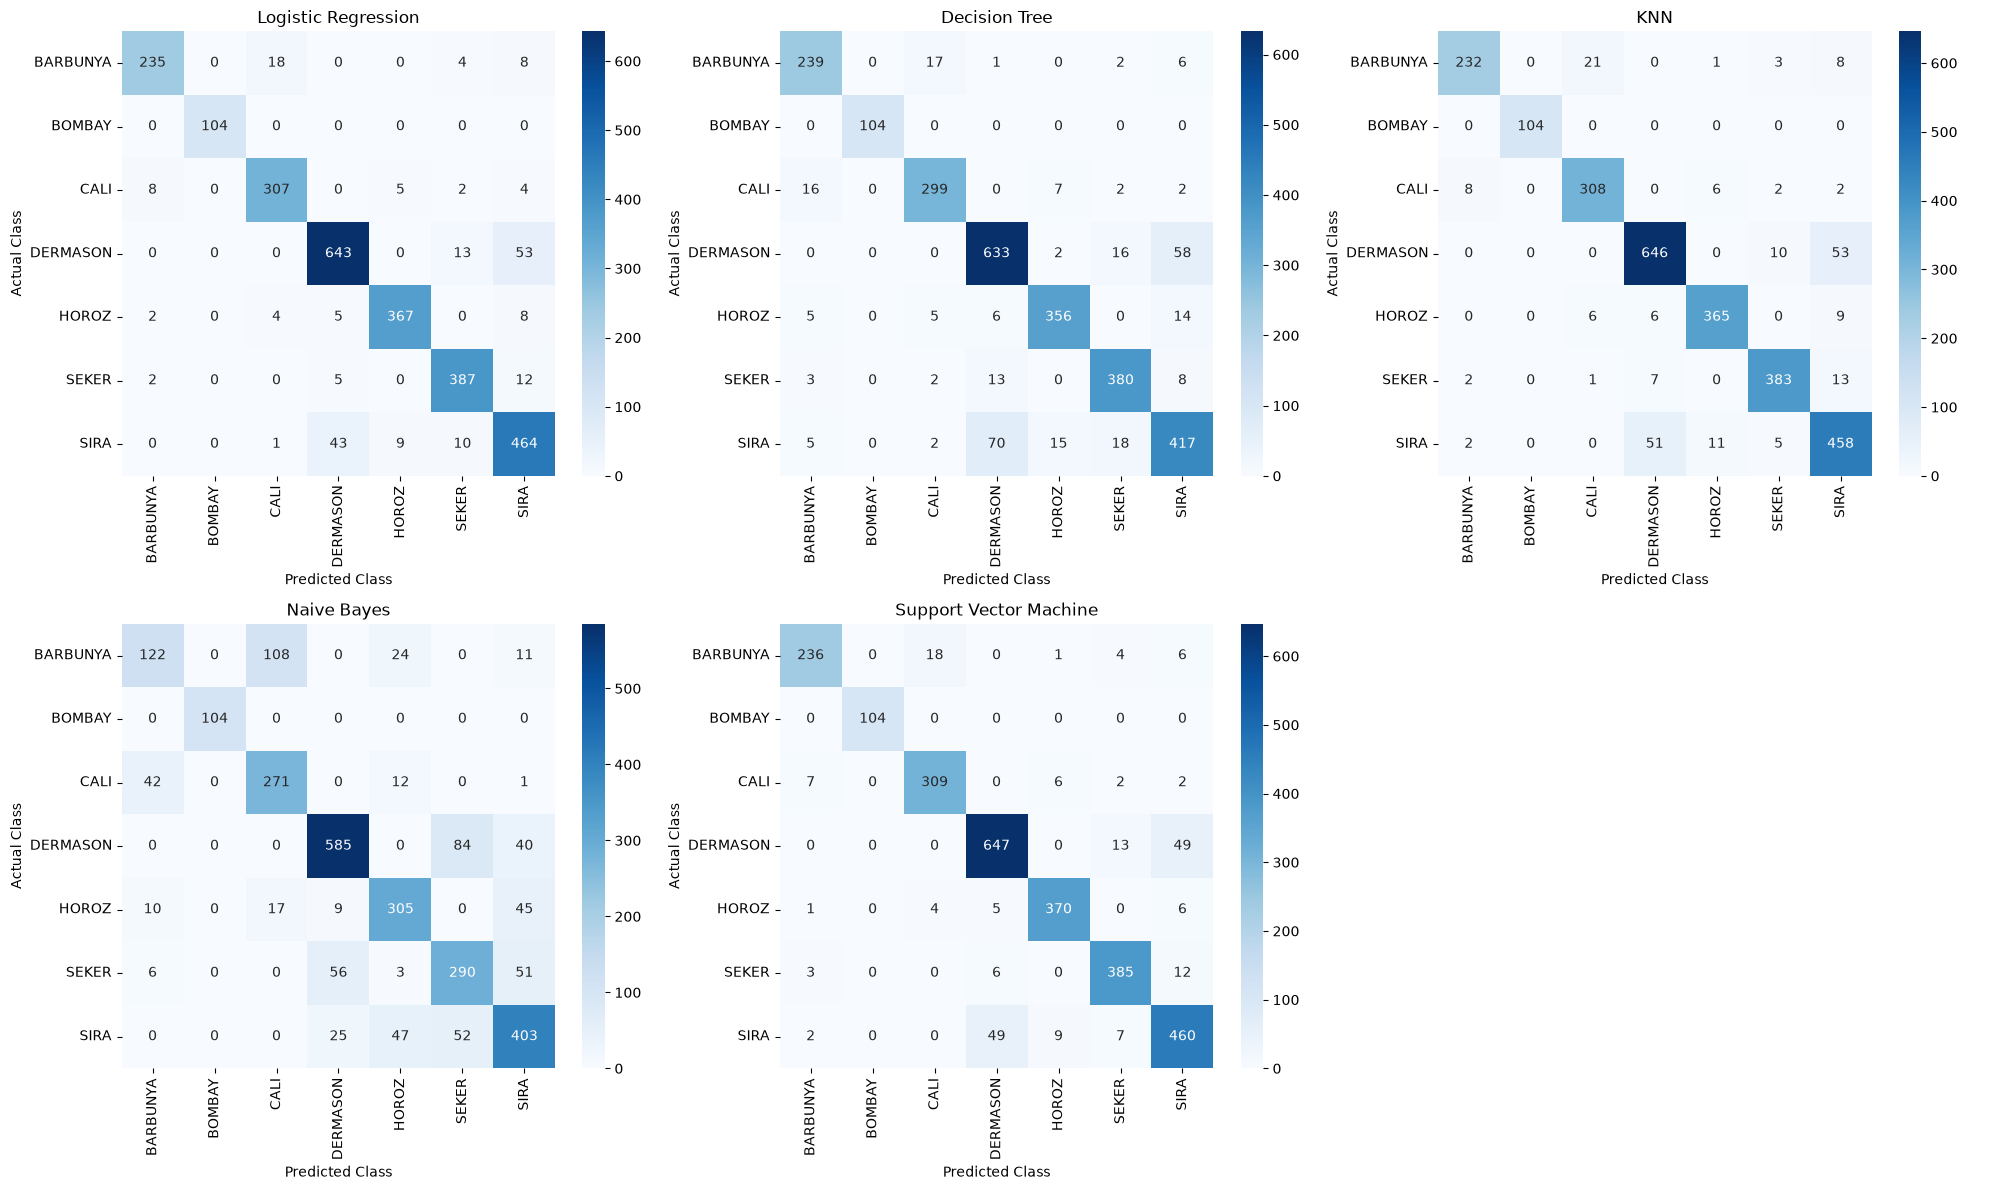

In [49]:
# ==========================================================
# CELL 20: CONFUSION MATRICES
# ==========================================================

class_names = trained_models[best_model_name].classes_

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 12)
)

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i]
    )

    axes[i].set_title(model_name)

    axes[i].set_xlabel('Predicted Class')

    axes[i].set_ylabel('Actual Class')

axes[5].axis('off')

plt.tight_layout()

plt.show()

In [51]:
# ==========================================================
# CELL 21: CLASSIFICATION REPORT
# ==========================================================

print("CLASSIFICATION REPORT FOR BEST MODEL")

print("\nSelected Model:", best_model_name)

print(
    classification_report(
        y_test,
        predictions[best_model_name],
        zero_division=0
    )
)

CLASSIFICATION REPORT FOR BEST MODEL

Selected Model: Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [53]:
# ==========================================================
# CELL 22: SAVING TRAINED MODELS
# ==========================================================

# Separate folder for newly reproduced models

REPRODUCED_MODEL_DIR = PROJECT_DIR / "model_reproduced"

REPRODUCED_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_filenames = {

    'Logistic Regression': 'logistic_regression.joblib',

    'Decision Tree': 'decision_tree.joblib',

    'KNN': 'knn.joblib',

    'Naive Bayes': 'naive_bayes.joblib',

    'Support Vector Machine': 'support_vector_machine.joblib'

}

for model_name, model in trained_models.items():

    filename = model_filenames[model_name]

    filepath = REPRODUCED_MODEL_DIR / filename

    joblib.dump(model, filepath)

    print(filename, "- SAVED SUCCESSFULLY")

print("\nALL FIVE MODELS SAVED!")

logistic_regression.joblib - SAVED SUCCESSFULLY
decision_tree.joblib - SAVED SUCCESSFULLY
knn.joblib - SAVED SUCCESSFULLY
naive_bayes.joblib - SAVED SUCCESSFULLY
support_vector_machine.joblib - SAVED SUCCESSFULLY

ALL FIVE MODELS SAVED!


In [55]:
# ==========================================================
# CELL 23: SAVING MODEL COMPARISON RESULTS
# ==========================================================

RESULT_FILE = PROJECT_DIR / "model_comparison_reproduced.csv"

results_df.to_csv(
    RESULT_FILE,
    index=False
)

print("Model comparison results saved successfully!")

print("Location:", RESULT_FILE)

Model comparison results saved successfully!
Location: /home/s2026aj05188/workspace/DryBeanProject/model_comparison_reproduced.csv


In [57]:
# ==========================================================
# CELL 24: VERIFYING PROJECT FILES
# ==========================================================

print("PROJECT DIRECTORY VERIFICATION")
print("--------------------------------")

for file in PROJECT_DIR.iterdir():

    if file.is_file():
        print(file.name, "- FOUND")

print("\nVERIFYING REPRODUCED MODELS")
print("--------------------------------")

for file in REPRODUCED_MODEL_DIR.iterdir():
    print(file.name, "- FOUND")

print("\nMODEL COMPARISON FILE")
print("--------------------------------")

print("Exists:", RESULT_FILE.exists())

PROJECT DIRECTORY VERIFICATION
--------------------------------
app.py - FOUND
requirements.txt - FOUND
model_comparison_reproduced.csv - FOUND
metadata.json - FOUND
model_comparison.csv - FOUND
README.md - FOUND
test_data.csv - FOUND
Dry_Bean_Dataset.csv - FOUND
Dry_Bean_Classification_ML.ipynb - FOUND

VERIFYING REPRODUCED MODELS
--------------------------------
naive_bayes.joblib - FOUND
logistic_regression.joblib - FOUND
decision_tree.joblib - FOUND
support_vector_machine.joblib - FOUND
knn.joblib - FOUND

MODEL COMPARISON FILE
--------------------------------
Exists: True


In [59]:
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Support Vector Machine,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059
1,Logistic Regression,0.9207,0.9934,0.9215,0.9207,0.9209,0.9042
2,KNN,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Decision Tree,0.8917,0.9330,0.8912,0.8917,0.8913,0.8691
4,Naive Bayes,0.7639,0.9644,0.7654,0.7639,0.7615,0.7154


In [61]:
print("BEST PERFORMING MODEL:", best_model_name)

BEST PERFORMING MODEL: Support Vector Machine
